
# Fraud Detection Learning Demo
This notebook demonstrates:
1. **Exploratory Data Analysis (EDA)** on a subset of the Credit Card Fraud dataset.
2. **Dimensionality Reduction** using PCA and t-SNE (preview) to visualize transaction patterns.
3. **Anomaly Detection** using statistical methods (Z-Score) and Machine Learning (Isolation Forest).
4. **Interpretability**: Visualizing anomalies and understanding fraud scores.

**Dataset**: [Credit Card Fraud Detection](https://www.kaggle.com/mlg-ulb/creditcardfraud) (subset of 10,000 rows).


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, RobustScaler
from scipy import stats

# Setup visual style
sns.set(style="whitegrid")
%matplotlib inline
print("Libraries installed and loaded!")


Libraries installed and loaded!



## 1. Load Data
We load the pre-prepared subset of 10,000 transactions. This subset maintains the original imbalance ratio of fraud vs. non-fraud transactions.


In [4]:

# Load dataset
try:
    df = pd.read_csv('data/fraud_subset.csv')
    print("Dataset loaded successfully.")
    print(f"Shape: {df.shape}")
except FileNotFoundError:
    print("Error: data/fraud_subset.csv not found. Please run prepare_subset.py first.")

# Display first few rows
display(df.head())

# Basic Stats
display(df.describe())

# Check Class Distribution
print("\nClass Distribution (0: Legitimate, 1: Fraud):")
print(df['Class'].value_counts())


Dataset loaded successfully.
Shape: (10000, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,44989.0,-1.371736,0.365828,1.626688,1.364716,-0.526173,-0.244988,-0.096144,0.577885,0.076863,...,0.140450,0.379893,-0.047632,0.426498,0.194872,-0.209037,0.277520,0.048077,80.44,0
1,79526.0,1.220008,0.161378,0.706575,0.760421,-0.864820,-1.330687,-0.019438,-0.161322,0.218103,...,-0.237785,-0.760175,0.218178,0.874783,0.099155,0.066100,-0.037581,0.021605,2.69,0
2,73003.0,1.275739,0.363387,-0.152200,1.126124,-0.134749,-1.240019,0.422188,-0.247006,0.010903,...,-0.019074,-0.089919,-0.122126,0.354122,0.787885,-0.290039,-0.020418,0.006836,1.49,0
3,107703.0,-0.574110,1.021022,2.266583,-0.101942,0.082950,-0.259461,0.415946,-0.099760,1.187640,...,-0.240616,-0.339340,-0.277514,-0.084676,0.314700,-0.700276,0.095518,0.078741,2.12,0
4,87750.0,-2.872232,2.641712,-1.519114,-2.942693,-0.039393,-0.955091,0.116400,1.236276,0.759272,...,-0.384475,-1.107494,0.045989,0.010915,0.404832,0.415378,0.472424,0.342083,1.00,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,95474.631400,-0.012279,0.003589,-0.012261,-0.013615,0.012788,0.002405,-0.007018,-0.004704,-0.006270,...,-0.006162,0.003634,0.008305,-0.008868,0.005263,-0.004166,-0.002417,-0.003240,89.150626,0.001700
std,47401.019242,1.920274,1.685518,1.499821,1.408700,1.403193,1.367924,1.277058,1.292861,1.086380,...,0.714934,0.729641,0.584639,0.607743,0.519865,0.484799,0.402051,0.296782,260.095128,0.041198
min,27.000000,-23.782185,-34.528546,-20.742660,-4.863246,-40.427726,-16.671588,-21.701600,-50.688419,-7.051016,...,-22.757540,-6.152177,-10.117548,-2.704672,-3.756198,-1.425404,-5.512517,-8.412267,0.000000,0.000000
25%,54890.250000,-0.942109,-0.598355,-0.896974,-0.849822,-0.693478,-0.768594,-0.560693,-0.209917,-0.640975,...,-0.230463,-0.542386,-0.161651,-0.363665,-0.319930,-0.328891,-0.071799,-0.053550,5.747500,0.000000
50%,85926.500000,-0.006031,0.083426,0.158033,-0.035978,-0.049858,-0.277022,0.038864,0.018932,-0.059210,...,-0.029315,0.012705,-0.013808,0.029780,0.019977,-0.061171,0.000129,0.011603,22.590000,0.000000
75%,139912.000000,1.315367,0.802514,1.032078,0.730186,0.646426,0.403568,0.578702,0.326827,0.587469,...,0.193147,0.533206,0.151366,0.444380,0.356809,0.235039,0.093053,0.079212,75.902500,0.000000
max,172784.000000,2.387980,11.069617,3.796873,9.739257,20.405657,23.917837,44.054461,12.101062,7.932015,...,14.718388,7.357255,12.557883,3.108809,4.881207,3.033586,6.507171,9.718743,10199.440000,1.000000



Class Distribution (0: Legitimate, 1: Fraud):
Class
0    9983
1      17
Name: count, dtype: int64



## 2. Preprocessing & Dimensionality Reduction
We standardize the features (V1-V28 are already PCA transformed from the original source, but 'Amount' is not). 
We will scale 'Amount' and 'Time' or drop 'Time' for this demo. We'll use all 'V' features plus Scaled Amount.


In [5]:

# Scale 'Amount'
rob_scaler = RobustScaler()
df['scaled_amount'] = rob_scaler.fit_transform(df['Amount'].values.reshape(-1,1))
df.drop(['Time', 'Amount'], axis=1, inplace=True)

# Define X (features) and y (labels for validation)
X = df.drop('Class', axis=1)
y = df['Class']

print("Features scaled. ready for analysis.")
display(X.head())


Features scaled. ready for analysis.


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,scaled_amount
0,-1.371736,0.365828,1.626688,1.364716,-0.526173,-0.244988,-0.096144,0.577885,0.076863,-0.608030,...,0.360651,0.140450,0.379893,-0.047632,0.426498,0.194872,-0.209037,0.277520,0.048077,0.824603
1,1.220008,0.161378,0.706575,0.760421,-0.864820,-1.330687,-0.019438,-0.161322,0.218103,-0.026235,...,-0.197437,-0.237785,-0.760175,0.218178,0.874783,0.099155,0.066100,-0.037581,0.021605,-0.283658
2,1.275739,0.363387,-0.152200,1.126124,-0.134749,-1.240019,0.422188,-0.247006,0.010903,0.101748,...,-0.278022,-0.019074,-0.089919,-0.122126,0.354122,0.787885,-0.290039,-0.020418,0.006836,-0.300763
3,-0.574110,1.021022,2.266583,-0.101942,0.082950,-0.259461,0.415946,-0.099760,1.187640,-1.393796,...,0.051463,-0.240616,-0.339340,-0.277514,-0.084676,0.314700,-0.700276,0.095518,0.078741,-0.291782
4,-2.872232,2.641712,-1.519114,-2.942693,-0.039393,-0.955091,0.116400,1.236276,0.759272,-0.053102,...,0.400208,-0.384475,-1.107494,0.045989,0.010915,0.404832,0.415378,0.472424,0.342083,-0.307747



### PCA Visualization (2D)
Reduce the 29 dimensions to 2 to visualize if Fraud cases (Class 1) form a distinct cluster.


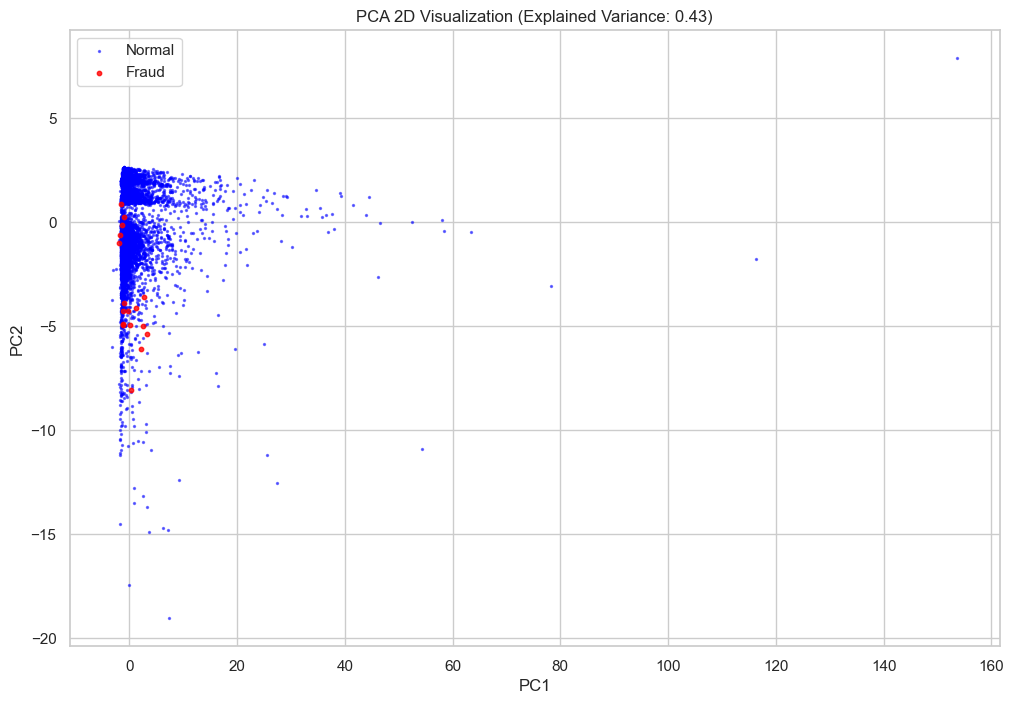

In [6]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(12, 8))
plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c='blue', label='Normal', alpha=0.5, s=2)
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c='red', label='Fraud', alpha=0.8, s=10)
plt.title(f'PCA 2D Visualization (Explained Variance: {pca.explained_variance_ratio_.sum():.2f})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()



## 3. Anomaly Detection: Statistical (Z-Score)
Simple method: Assume anomalies are far from the mean.
We'll calculate the mean Z-score across all important features or look at specific ones.
For demonstration, let's look at the average Z-score magnitude across all features for each transaction.


In [7]:

# Calculate Z-scores for all features
z_scores = np.abs(stats.zscore(X))
# Check if any feature has Z-score > 3
outliers_z = (z_scores > 3).any(axis=1)

print(f"Number of statistical outliers detected (Z > 3 in any feature): {outliers_z.sum()}")

# Visualize Fraud overlap
df['z_outlier'] = outliers_z
pd.crosstab(df['Class'], df['z_outlier'])


Number of statistical outliers detected (Z > 3 in any feature): 1303


z_outlier,False,True
Class,,
0,8696,1287
1,1,16



## 4. Isolation Forest
Unsupervised learning robust to outliers. The model isolates observations by randomly selecting a feature and then randomly selecting a split value between the maximum and minimum values of the selected feature.


In [8]:

# Train Isolation Forest
# contamination='auto' or 0.01 (approx fraud rate)
iso_forest = IsolationForest(n_estimators=100, contamination=0.01, random_state=42)
iso_forest.fit(X)

# Predict (-1 is outlier, 1 is inlier)
scores = iso_forest.decision_function(X) # lower is more anomalous
preds = iso_forest.predict(X)

df['anomaly_score'] = scores
df['prediction'] = preds

# Map -1 to 1 (Fraud) and 1 to 0 (Normal) for comparison
df['pred_class'] = df['prediction'].apply(lambda x: 1 if x == -1 else 0)

display(df[['Class', 'pred_class', 'anomaly_score']].head())

# Evaluation
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y, df['pred_class']))
print("\nClassification Report:")
print(classification_report(y, df['pred_class']))


,Class,pred_class,anomaly_score
0,0,0,0.218877
1,0,0,0.214893
2,0,0,0.216750
3,0,0,0.173524
4,0,0,0.168557


Confusion Matrix:
[[9893   90]
 [   7   10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      9983
           1       0.10      0.59      0.17        17

    accuracy                           0.99     10000
   macro avg       0.55      0.79      0.58     10000
weighted avg       1.00      0.99      0.99     10000




### Visualization of Anomaly Scores
Let's modify the PCA plot to color by Anomaly Score.


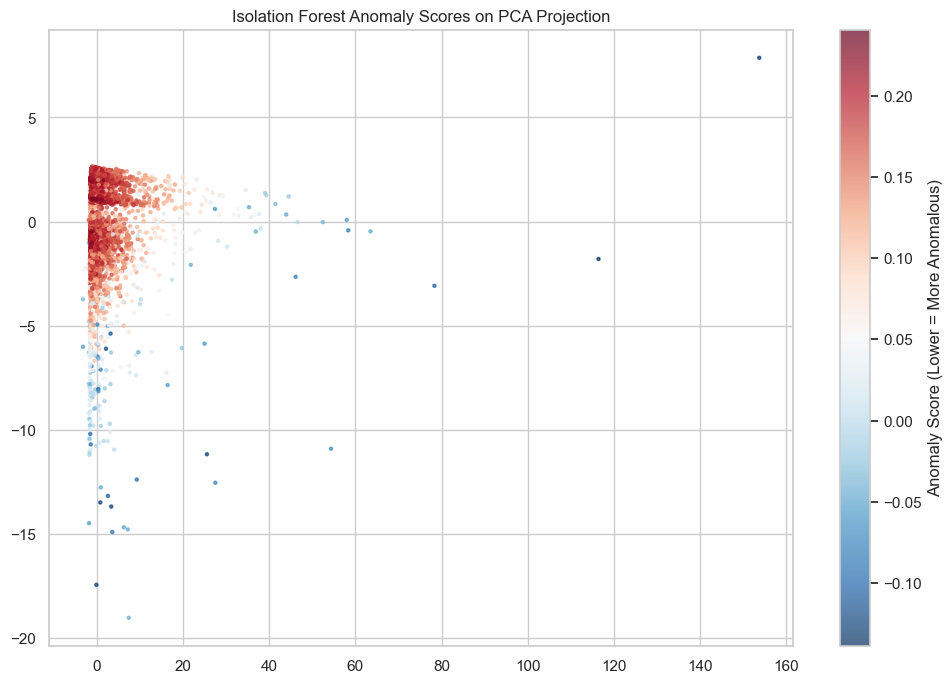

In [9]:

plt.figure(figsize=(12, 8))
sc = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['anomaly_score'], cmap='RdBu_r', s=5, alpha=0.7)
plt.colorbar(sc, label='Anomaly Score (Lower = More Anomalous)')
plt.title('Isolation Forest Anomaly Scores on PCA Projection')
plt.show()



## 5. Interpretability: Extracting Rules from Anomalies
The Isolation Forest gives us a score, but it's a "Black Box". 
To understand **WHY** certain points were flagged, we can train a simple **Decision Tree** (Surrogate Model) to predict the *Anomaly Label* using the original features.
This will give us human-readable rules like: "If V14 < -3.5 AND V4 > 2.1 THEN Anomaly".


Rules derived from Anomalies:
|--- V1 <= -6.50
|   |--- V10 <= -1.73
|   |   |--- class: 1
|   |--- V10 >  -1.73
|   |   |--- V8 <= -0.81
|   |   |   |--- class: 1
|   |   |--- V8 >  -0.81
|   |   |   |--- class: 0
|--- V1 >  -6.50
|   |--- V7 <= -5.93
|   |   |--- V26 <= 0.76
|   |   |   |--- class: 1
|   |   |--- V26 >  0.76
|   |   |   |--- class: 0
|   |--- V7 >  -5.93
|   |   |--- scaled_amount <= 35.17
|   |   |   |--- class: 0
|   |   |--- scaled_amount >  35.17
|   |   |   |--- class: 1


Top 5 Features driving the Anomalies:
V1               0.514288
V7               0.176333
V10              0.115539
scaled_amount    0.093261
V8               0.084423
dtype: float64


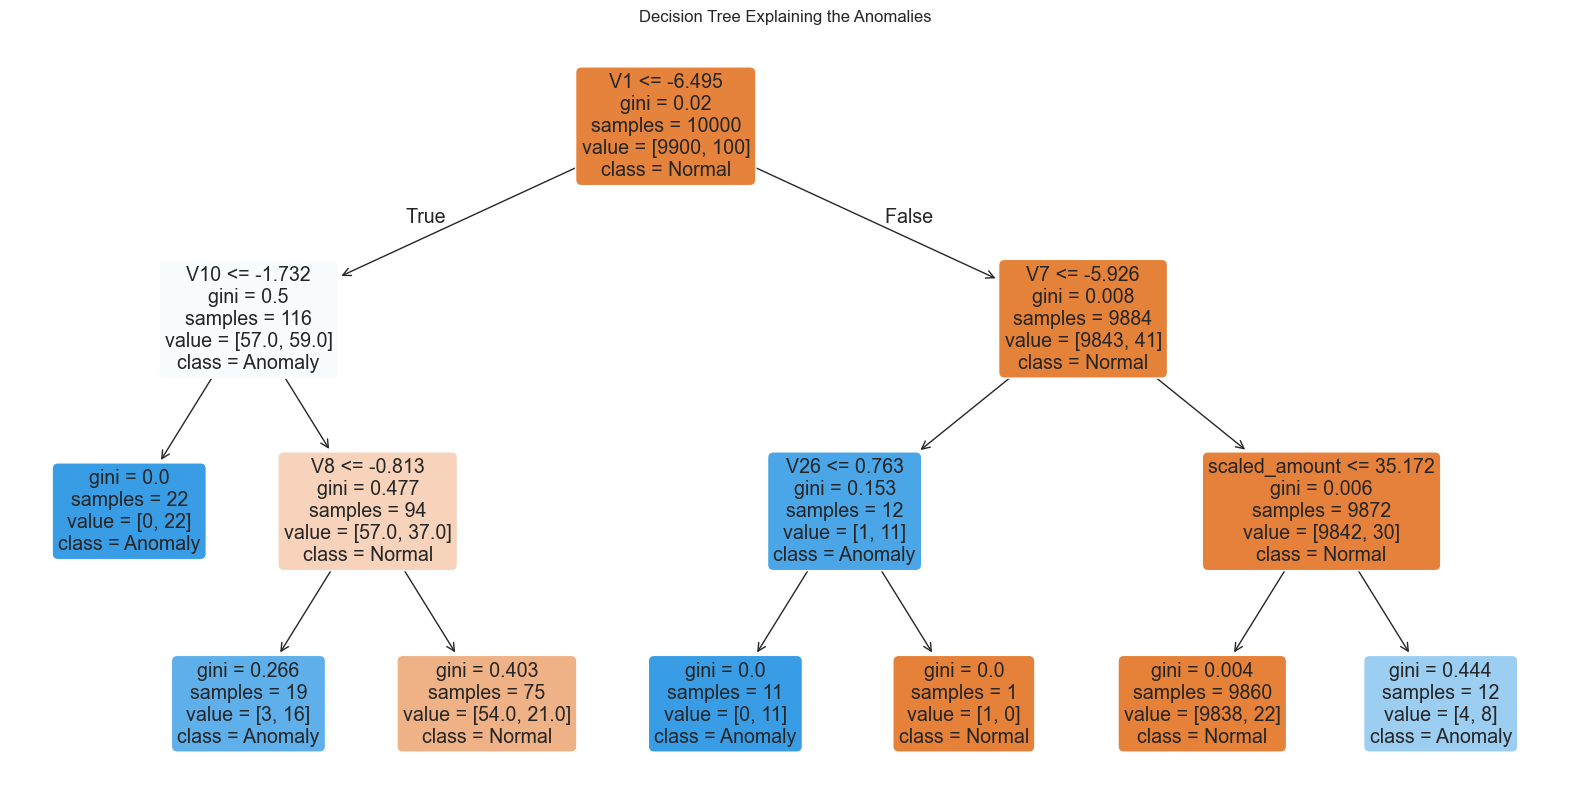

In [10]:

from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# We want to explain the 'prediction' column (-1 for outlier, 1 for inlier)
# Let's map it to 1 (Anomaly) and 0 (Normal) for the Tree
y_explain = df['pred_class'] # This is our target for the explanation tree

# Train a shallow tree (depth=3) for simple rules
dt_explainer = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_explainer.fit(X, y_explain)

# Print the rules
print("Rules derived from Anomalies:")
print(export_text(dt_explainer, feature_names=list(X.columns)))

# Visualize importance
feat_importances = pd.Series(dt_explainer.feature_importances_, index=X.columns)
print("\nTop 5 Features driving the Anomalies:")
print(feat_importances.nlargest(5))

# Plot the tree (Optional)
plt.figure(figsize=(20,10))
plot_tree(dt_explainer, feature_names=list(X.columns), filled=True, class_names=['Normal', 'Anomaly'], rounded=True)
plt.title("Decision Tree Explaining the Anomalies")
plt.show()
